In [7]:
import pandas as pd 
import numpy as numpy
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from mlflow.models import infer_signature


In [8]:
df = pd.read_csv('ai_ds_job_salaries_2026.csv')
df = pd.DataFrame(df)
df.head(15)

,job_title,experience_level,employment_type,company_size,company_location,employee_residence,industry,remote_ratio,years_experience,education_level,...,ai_tools_hours_per_week,salary_currency,salary_usd,equity_offered_pct,bonus_pct,job_satisfaction_score,interviews_to_offer,switched_jobs_last_year,upskilling_hours_per_month,fears_ai_automation_score
0,Data Analyst,Lead,Part-time,S,IN,AU,Finance,0,14.4,Bachelors,...,12.5,INR,23844,0.505,11.6,5.5,8,True,2.2,7.4
1,Research Scientist,Senior,Full-time,L,US,US,Retail,50,7.6,Masters,...,2.1,USD,170132,0.054,2.9,7.0,3,False,8.2,5.3
2,Machine Learning Engineer,Entry,Full-time,M,US,US,Government,0,0.0,Bootcamp,...,5.1,USD,83059,0.191,7.5,5.9,1,False,2.8,6.8
3,Data Engineer,Senior,Full-time,M,BR,IN,Government,100,9.7,Masters,...,2.0,BRL,29531,0.102,9.3,5.6,5,False,7.8,5.0
4,Data Engineer,Mid,Full-time,M,US,US,Education,0,3.2,Bachelors,...,4.0,USD,70105,0.064,10.6,4.6,4,False,9.1,5.1
5,Analytics Engineer,Senior,Full-time,M,SG,SG,Finance,100,11.6,Masters,...,17.4,SGD,97827,0.131,12.2,7.9,3,False,12.2,4.3
6,Business Intelligence Analyst,Senior,Full-time,M,US,US,Technology,0,9.8,Bachelors,...,0.5,USD,120062,0.039,13.0,5.5,6,False,10.9,6.4
7,Data Analyst,Entry,Full-time,M,US,US,Retail,0,1.4,Masters,...,4.2,USD,64165,0.187,12.7,7.3,3,True,14.5,6.4
8,Research Scientist,Mid,Full-time,M,AU,AU,Finance,0,2.2,Masters,...,6.6,AUD,112968,0.036,11.0,7.7,3,False,3.0,2.3
9,Data Engineer,Entry,Part-time,L,GB,GB,Healthcare,0,2.8,Self-taught,...,2.0,GBP,26464,0.044,0.0,6.2,5,False,9.3,5.4


In [9]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   job_title                   5000 non-null   object 
 1   experience_level            5000 non-null   object 
 2   employment_type             5000 non-null   object 
 3   company_size                5000 non-null   object 
 4   company_location            5000 non-null   object 
 5   employee_residence          5000 non-null   object 
 6   industry                    5000 non-null   object 
 7   remote_ratio                5000 non-null   int64  
 8   years_experience            5000 non-null   float64
 9   education_level             5000 non-null   object 
 10  primary_language            5000 non-null   object 
 11  has_ml_in_title             5000 non-null   bool   
 12  manages_people              5000 non-null   bool   
 13  team_size                   5000 

(5000, 27)

In [10]:
df.describe()

,remote_ratio,years_experience,team_size,certifications_count,weekly_hours,ai_tools_hours_per_week,salary_usd,equity_offered_pct,bonus_pct,job_satisfaction_score,interviews_to_offer,upskilling_hours_per_month,fears_ai_automation_score
count,5000.00000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.08000,8.361440,7.93620,1.820400,44.345400,8.437400,98605.406200,0.139020,10.802720,6.685320,5.230800,8.680740,4.846080
std,41.45428,4.820808,2.64793,1.344212,6.142761,5.503637,55369.310473,0.184243,5.152959,1.364302,2.412695,4.422549,1.725924
min,0.00000,0.000000,1.00000,0.000000,24.400000,0.000000,12000.000000,0.000000,0.000000,1.100000,1.000000,0.000000,1.000000
25%,0.00000,4.800000,6.00000,1.000000,40.100000,3.300000,55592.750000,0.017000,7.100000,5.800000,3.000000,5.600000,3.700000
50%,50.00000,8.100000,8.00000,2.000000,44.400000,8.500000,90572.000000,0.072000,10.600000,6.700000,5.000000,8.700000,4.800000
75%,100.00000,11.500000,10.00000,3.000000,48.500000,12.625000,129657.750000,0.175000,14.200000,7.600000,7.000000,11.700000,6.000000
max,100.00000,23.700000,19.00000,8.000000,67.300000,25.200000,372347.000000,1.264000,30.800000,10.000000,16.000000,26.200000,10.000000


<Axes: xlabel='upskilling_hours_per_month', ylabel='salary_usd'>

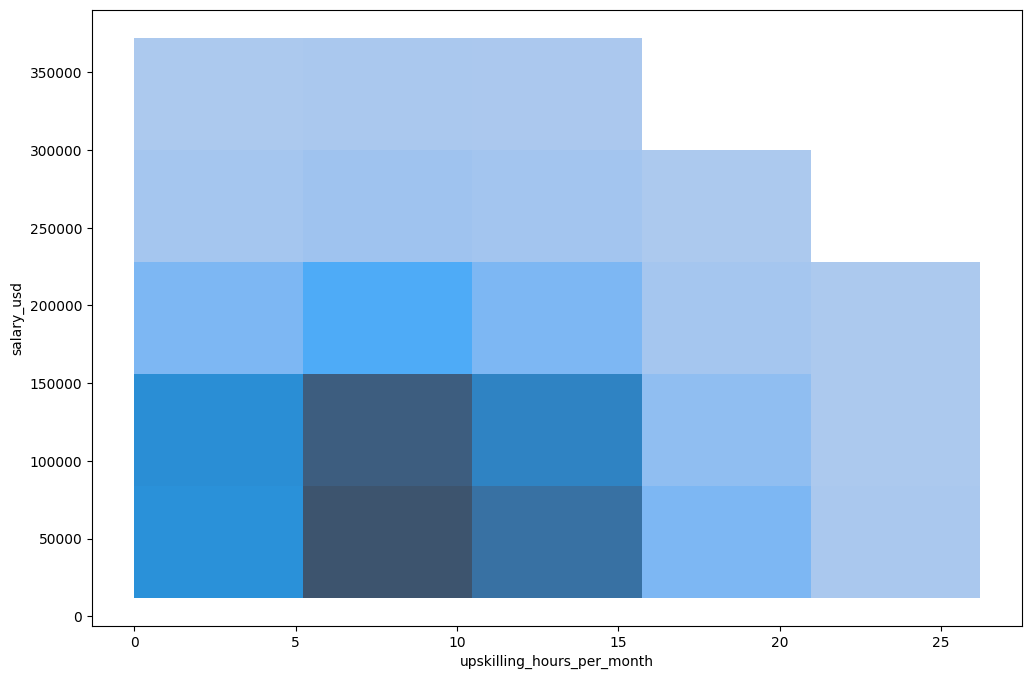

In [11]:
plt.figure(figsize = (12,8))
sns.histplot(df,x= df['upskilling_hours_per_month'],y=df['salary_usd'], kde=True, bins=5)

<Axes: xlabel='education_level', ylabel='salary_usd'>

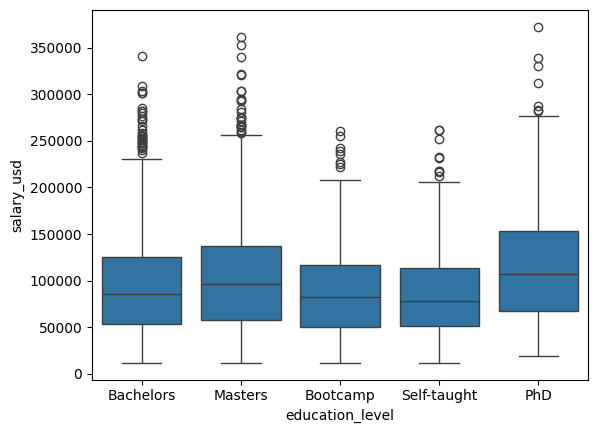

In [12]:
sns.boxplot(df, x=df['education_level'], y= df['salary_usd'] )

<Axes: xlabel='ai_tools_hours_per_week', ylabel='salary_usd'>

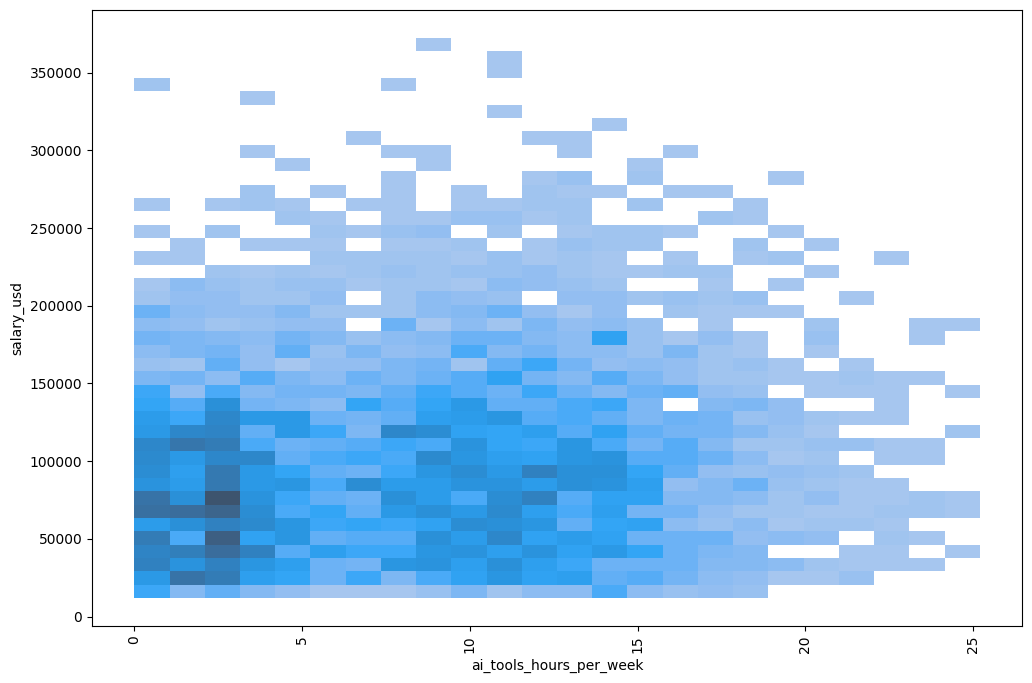

In [13]:
plt.figure(figsize = (12,8))
plt.xticks(rotation = 90)
sns.histplot(df, x=df['ai_tools_hours_per_week'], y= df['salary_usd'] )


<Axes: xlabel='salary_currency', ylabel='salary_usd'>

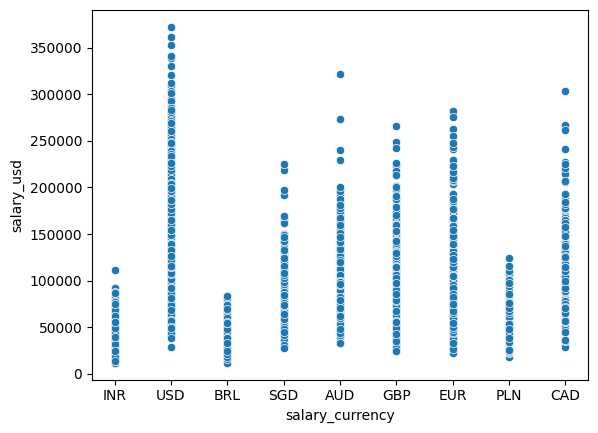

In [14]:
sns.scatterplot(df, x=df['salary_currency'], y= df['salary_usd'] )

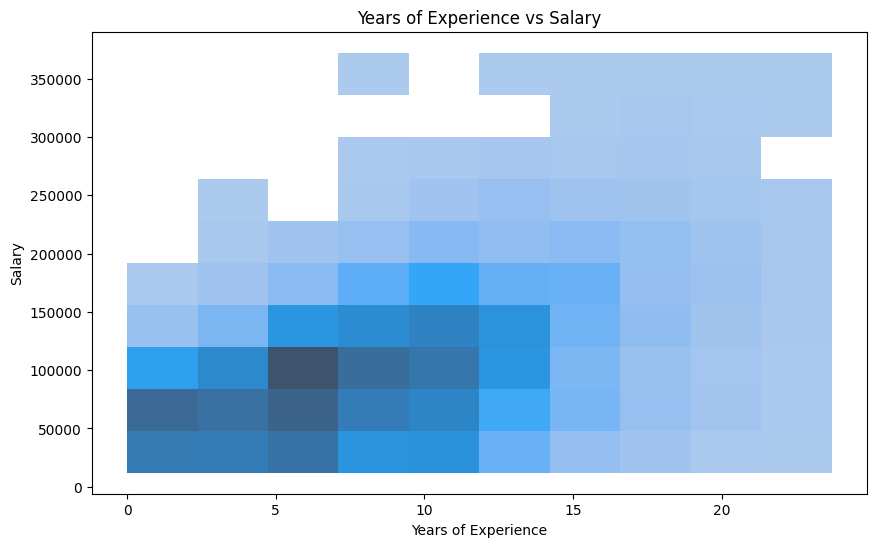

In [15]:
plt.figure(figsize=(10,6))

sns.histplot(
    x=df["years_experience"],
    y=df["salary_usd"],
    data=df,
    bins = 10,
    kde =True
   
)

plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")

plt.show()

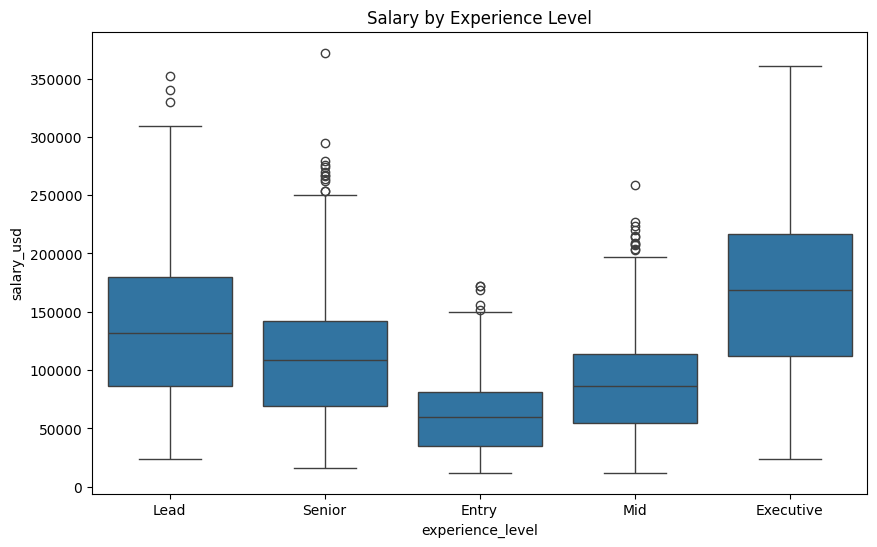

In [10]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x="experience_level",
    y="salary_usd",
    data=df
)

plt.title("Salary by Experience Level")

plt.show()

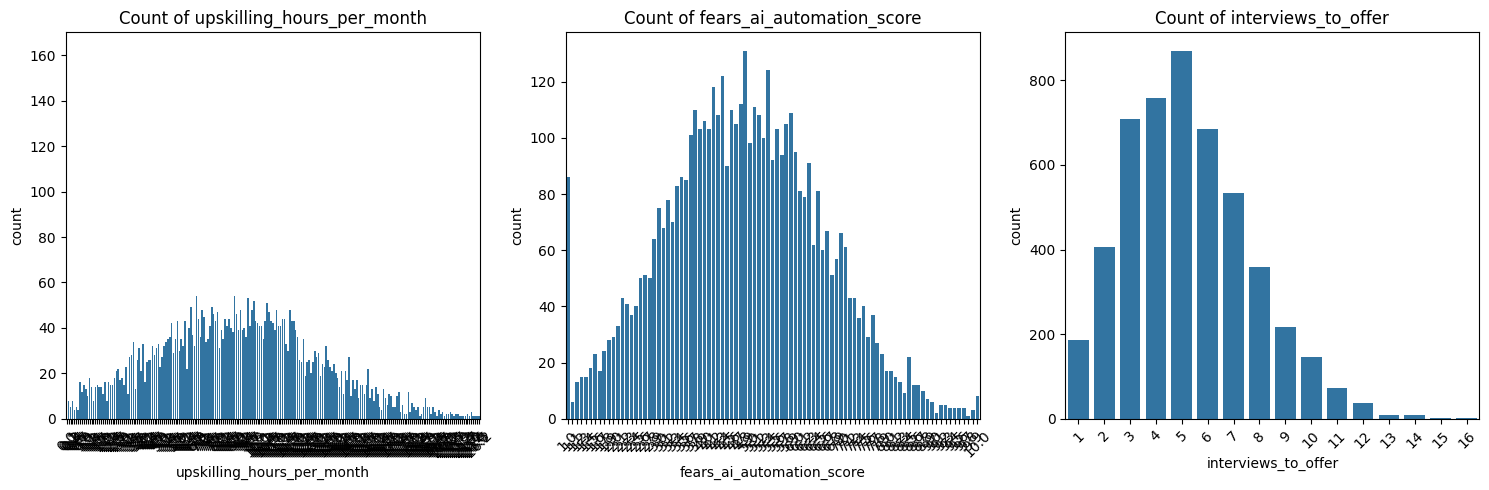

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

cols = df[['upskilling_hours_per_month','fears_ai_automation_score','interviews_to_offer']]

for i, col in enumerate(cols):
    sns.countplot(x=col, data=df, ax=axes[i])
    axes[i].set_title(f"Count of {col}")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

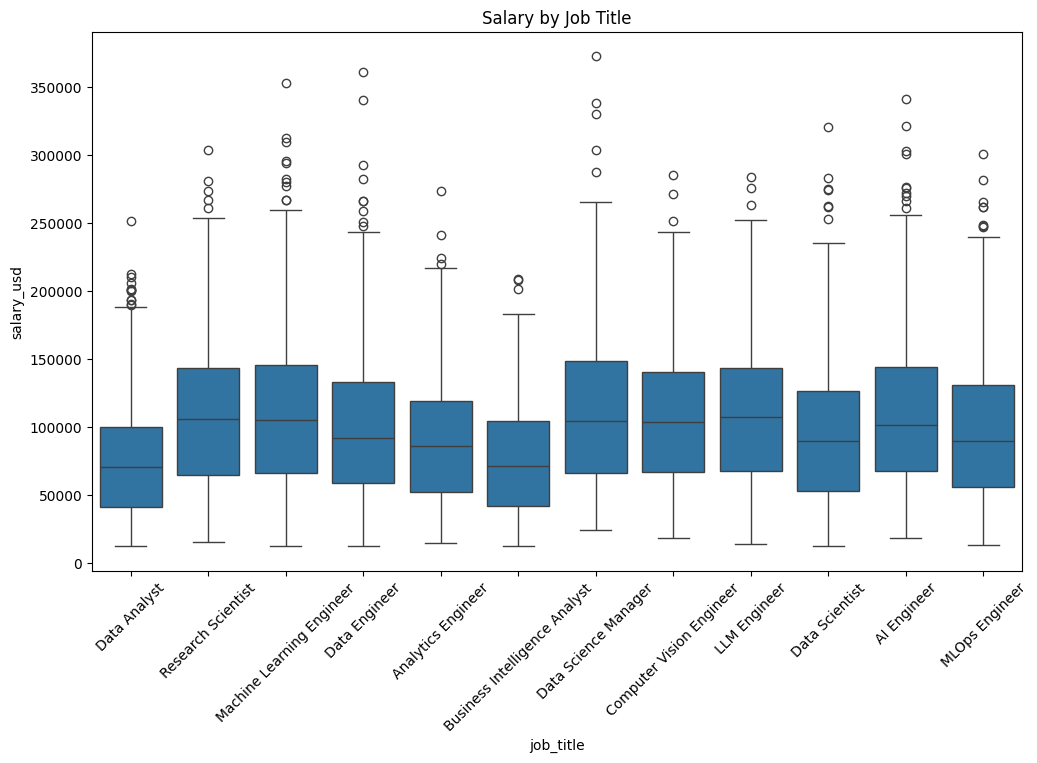

In [12]:
plt.figure(figsize=(12,7))

sns.boxplot(
    x="job_title",
    y="salary_usd",
    data=df
)

plt.xticks(rotation=45)
plt.title("Salary by Job Title")

plt.show()

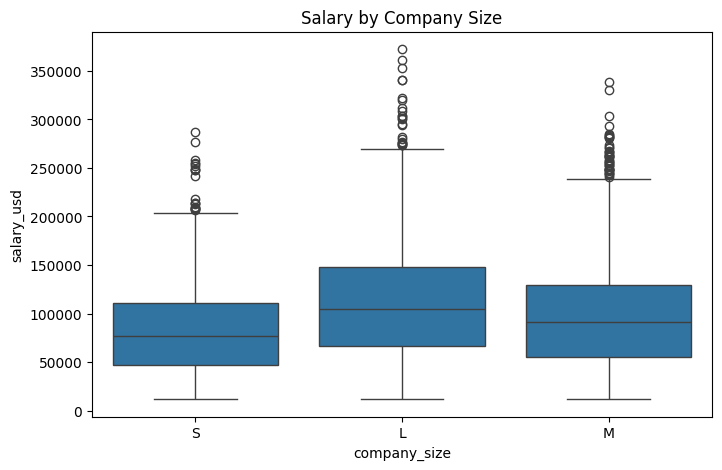

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="company_size",
    y="salary_usd",
    data=df
)

plt.title("Salary by Company Size")

plt.show()

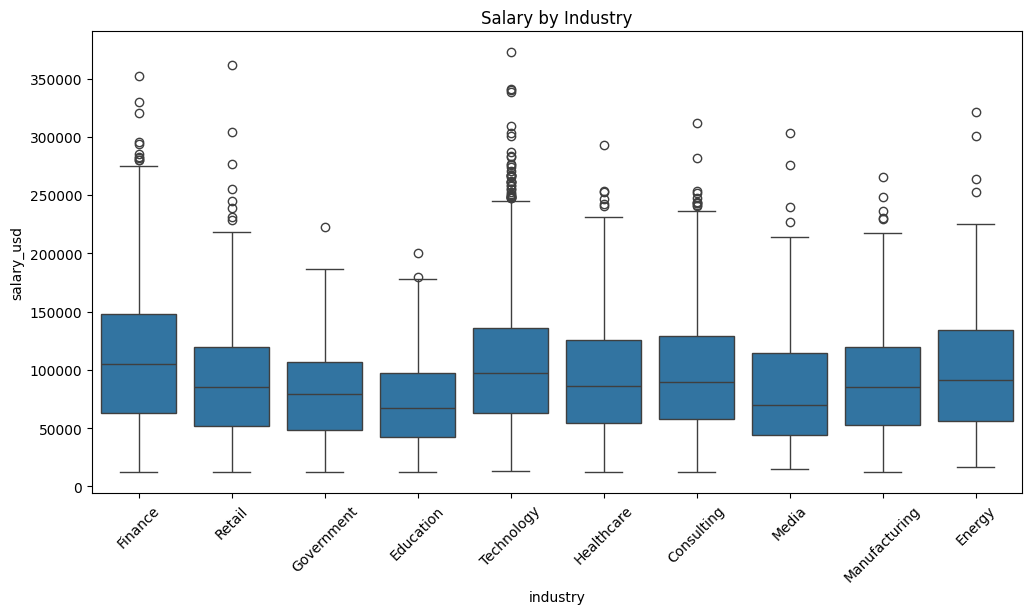

In [14]:
plt.figure(figsize=(12,6))

sns.boxplot(
    x="industry",
    y="salary_usd",
    data=df
)

plt.xticks(rotation=45)
plt.title("Salary by Industry")

plt.show()

In [16]:
df.sample(10)

,job_title,experience_level,employment_type,company_size,company_location,employee_residence,industry,remote_ratio,years_experience,education_level,...,ai_tools_hours_per_week,salary_currency,salary_usd,equity_offered_pct,bonus_pct,job_satisfaction_score,interviews_to_offer,switched_jobs_last_year,upskilling_hours_per_month,fears_ai_automation_score
2863,Analytics Engineer,Entry,Full-time,M,NL,NL,Technology,0,0.2,Bachelors,...,6.1,EUR,57875,0.022,14.6,5.8,1,True,11.0,2.9
1832,Machine Learning Engineer,Senior,Full-time,L,IN,IN,Education,0,11.2,Bootcamp,...,12.2,INR,46138,0.028,7.0,5.1,9,True,11.1,4.7
2700,Data Science Manager,Senior,Full-time,M,IN,IN,Technology,100,6.8,Bootcamp,...,13.6,INR,66490,0.046,11.1,6.3,6,False,5.8,2.1
760,Business Intelligence Analyst,Senior,Full-time,M,GB,GB,Media,50,8.1,Bootcamp,...,2.3,GBP,76667,0.000,11.6,5.4,4,False,4.5,4.4
4761,Data Engineer,Mid,Full-time,S,IN,IN,Consulting,0,7.1,Bachelors,...,21.2,INR,26573,0.396,9.3,6.9,6,False,8.0,5.6
1555,Data Scientist,Mid,Part-time,L,US,US,Energy,100,5.2,Masters,...,12.0,USD,64072,0.098,10.1,4.4,7,False,9.7,6.8
164,Data Engineer,Entry,Full-time,L,FR,FR,Retail,0,2.5,Masters,...,12.9,EUR,54863,0.044,4.3,6.2,1,False,4.4,4.9
901,Data Science Manager,Senior,Full-time,M,IN,US,Consulting,0,9.2,Bachelors,...,6.7,INR,64059,0.000,11.7,5.7,8,False,7.2,4.7
3147,Research Scientist,Senior,Freelance,L,IN,IN,Energy,0,8.0,Bootcamp,...,18.2,INR,35479,0.019,8.5,5.5,8,False,7.7,3.8
555,Business Intelligence Analyst,Entry,Contract,L,US,US,Education,100,3.7,Masters,...,14.2,USD,70522,0.064,13.0,7.3,5,True,3.0,3.7


In [17]:
df.columns

Index(['job_title', 'experience_level', 'employment_type', 'company_size',
       'company_location', 'employee_residence', 'industry', 'remote_ratio',
       'years_experience', 'education_level', 'primary_language',
       'has_ml_in_title', 'manages_people', 'team_size',
       'certifications_count', 'weekly_hours', 'uses_ai_tools_daily',
       'ai_tools_hours_per_week', 'salary_currency', 'salary_usd',
       'equity_offered_pct', 'bonus_pct', 'job_satisfaction_score',
       'interviews_to_offer', 'switched_jobs_last_year',
       'upskilling_hours_per_month', 'fears_ai_automation_score'],
      dtype='object')

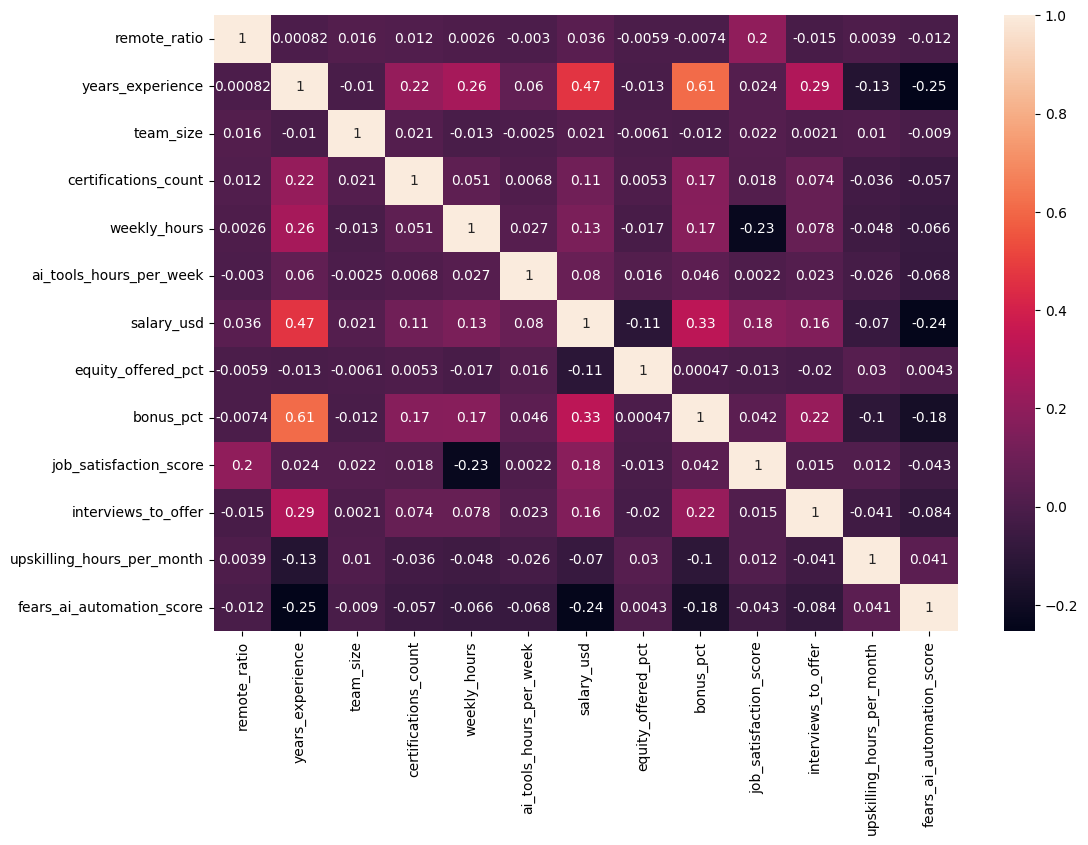

In [18]:
plt.figure(figsize =(12,8))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True)
plt.show()

In [19]:
df.isnull().sum()

job_title                     0
experience_level              0
employment_type               0
company_size                  0
company_location              0
employee_residence            0
industry                      0
remote_ratio                  0
years_experience              0
education_level               0
primary_language              0
has_ml_in_title               0
manages_people                0
team_size                     0
certifications_count          0
weekly_hours                  0
uses_ai_tools_daily           0
ai_tools_hours_per_week       0
salary_currency               0
salary_usd                    0
equity_offered_pct            0
bonus_pct                     0
job_satisfaction_score        0
interviews_to_offer           0
switched_jobs_last_year       0
upskilling_hours_per_month    0
fears_ai_automation_score     0
dtype: int64

In [20]:
df.corr(numeric_only=True)

,remote_ratio,years_experience,has_ml_in_title,manages_people,team_size,certifications_count,weekly_hours,uses_ai_tools_daily,ai_tools_hours_per_week,salary_usd,equity_offered_pct,bonus_pct,job_satisfaction_score,interviews_to_offer,switched_jobs_last_year,upskilling_hours_per_month,fears_ai_automation_score
remote_ratio,1.000000,0.000817,-0.010522,0.007922,0.015932,0.012334,0.002597,0.005077,-0.003021,0.036407,-0.005855,-0.007357,0.200945,-0.015229,-0.029264,0.003872,-0.011549
years_experience,0.000817,1.000000,-0.029448,0.592994,-0.010405,0.215552,0.260733,0.093116,0.060093,0.466250,-0.012635,0.609849,0.023550,0.290221,-0.001382,-0.132696,-0.253683
has_ml_in_title,-0.010522,-0.029448,1.000000,-0.014634,0.027861,0.003803,-0.039228,0.191395,0.147912,0.159620,0.018942,-0.014691,0.040560,-0.017542,-0.008986,-0.008611,-0.332091
manages_people,0.007922,0.592994,-0.014634,1.000000,0.000312,0.151355,0.159110,0.062976,0.044497,0.317853,-0.016888,0.405992,0.010880,0.198174,-0.008522,-0.102998,-0.171991
team_size,0.015932,-0.010405,0.027861,0.000312,1.000000,0.021003,-0.012687,-0.013505,-0.002507,0.021266,-0.006089,-0.012298,0.022383,0.002055,-0.005578,0.010185,-0.009026
certifications_count,0.012334,0.215552,0.003803,0.151355,0.021003,1.000000,0.050964,0.024908,0.006781,0.107841,0.005295,0.168985,0.018491,0.074464,-0.008716,-0.035547,-0.057315
weekly_hours,0.002597,0.260733,-0.039228,0.159110,-0.012687,0.050964,1.000000,0.048152,0.026934,0.133520,-0.017489,0.173516,-0.227398,0.077898,0.047563,-0.047595,-0.066211
uses_ai_tools_daily,0.005077,0.093116,0.191395,0.062976,-0.013505,0.024908,0.048152,1.000000,0.722987,0.110620,-0.000686,0.063192,-0.011997,0.020416,-0.011119,-0.040459,-0.088385
ai_tools_hours_per_week,-0.003021,0.060093,0.147912,0.044497,-0.002507,0.006781,0.026934,0.722987,1.000000,0.080282,0.015728,0.046455,0.002153,0.022598,-0.014456,-0.026349,-0.067841
salary_usd,0.036407,0.466250,0.159620,0.317853,0.021266,0.107841,0.133520,0.110620,0.080282,1.000000,-0.111595,0.328451,0.179104,0.155130,-0.031533,-0.069662,-0.241418


In [21]:
df[['job_title']].value_counts()

job_title                    
Data Scientist                   709
Data Engineer                    682
Data Analyst                     627
Machine Learning Engineer        593
AI Engineer                      506
Analytics Engineer               317
MLOps Engineer                   306
Business Intelligence Analyst    293
Research Scientist               269
LLM Engineer                     242
Data Science Manager             238
Computer Vision Engineer         218
Name: count, dtype: int64

In [21]:
df['experience_level'].value_counts()

experience_level
Mid          1613
Senior       1520
Entry         985
Lead          656
Executive     226
Name: count, dtype: int64

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df["salary_usd"].describe()

count      5000.000000
mean      98605.406200
std       55369.310473
min       12000.000000
25%       55592.750000
50%       90572.000000
75%      129657.750000
max      372347.000000
Name: salary_usd, dtype: float64

In [24]:
df.select_dtypes(include="object").nunique()

job_title             12
experience_level       5
employment_type        4
company_size           3
company_location      12
employee_residence    12
industry              10
education_level        5
primary_language       7
salary_currency        9
dtype: int64

In [22]:
df.nunique()

job_title                       12
experience_level                 5
employment_type                  4
company_size                     3
company_location                12
employee_residence              12
industry                        10
remote_ratio                     3
years_experience               230
education_level                  5
primary_language                 7
has_ml_in_title                  2
manages_people                   2
team_size                       19
certifications_count             9
weekly_hours                   344
uses_ai_tools_daily              2
ai_tools_hours_per_week        240
salary_currency                  9
salary_usd                    4928
equity_offered_pct             684
bonus_pct                      258
job_satisfaction_score          80
interviews_to_offer             16
switched_jobs_last_year          2
upskilling_hours_per_month     217
fears_ai_automation_score       91
dtype: int64

In [23]:
# ordinal encoding

df['experience_level']= df['experience_level'].map({'Entry': 0, 'Mid': 1, 'Senior': 2, 'Lead': 3, 'Executive': 4})

In [24]:
df['company_size']= df['company_size'].map({'S': 0, 'M': 1, 'L': 2})

In [25]:
df["has_ml_in_title"] = df["has_ml_in_title"].astype(int)

In [26]:
df["manages_people"] = df["manages_people"].astype(int)

<Axes: xlabel='primary_language', ylabel='salary_usd'>

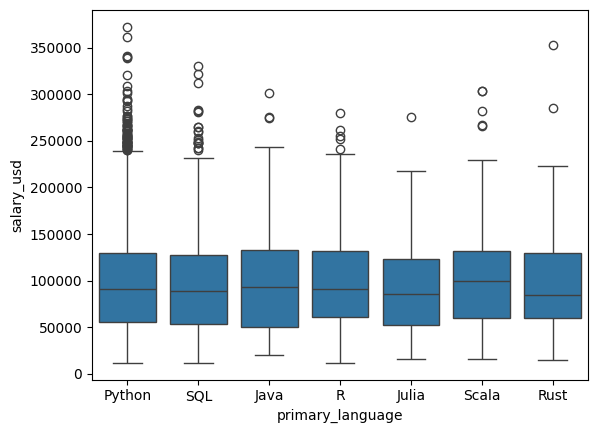

In [27]:
sns.boxplot(data = df, x = df['primary_language'], y = df['salary_usd'])

In [28]:
df.columns

Index(['job_title', 'experience_level', 'employment_type', 'company_size',
       'company_location', 'employee_residence', 'industry', 'remote_ratio',
       'years_experience', 'education_level', 'primary_language',
       'has_ml_in_title', 'manages_people', 'team_size',
       'certifications_count', 'weekly_hours', 'uses_ai_tools_daily',
       'ai_tools_hours_per_week', 'salary_currency', 'salary_usd',
       'equity_offered_pct', 'bonus_pct', 'job_satisfaction_score',
       'interviews_to_offer', 'switched_jobs_last_year',
       'upskilling_hours_per_month', 'fears_ai_automation_score'],
      dtype='object')

In [45]:
pd.crosstab(
    df["experience_level"],
    df["manages_people"],
    normalize="index"
)

manages_people,0,1
experience_level,,
0,0.935025,0.064975
1,0.936764,0.063236
2,0.939474,0.060526
3,0.000000,1.000000
4,0.000000,1.000000


In [46]:
pd.crosstab(
    df["experience_level"],
    df["years_experience"],
    normalize="index"
)

years_experience,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0,2.1,2.2,2.3,2.4,2.5,2.6,2.7,2.8,2.9,3.0,3.1,3.2,3.3,3.4,3.5,3.6,3.7,3.8,3.9,4.0,4.1,4.2,4.3,4.4,4.5,4.6,4.7,4.8,4.9,5.0,5.1,5.2,5.3,5.4,5.5,5.6,5.7,5.8,5.9,6.0,6.1,6.2,6.3,6.4,6.5,6.6,6.7,6.8,6.9,7.0,7.1,7.2,7.3,7.4,7.5,7.6,7.7,7.8,7.9,8.0,8.1,8.2,8.3,8.4,8.5,8.6,8.7,8.8,8.9,9.0,9.1,9.2,9.3,9.4,9.5,9.6,9.7,9.8,9.9,10.0,10.1,10.2,10.3,10.4,10.5,10.6,10.7,10.8,10.9,11.0,11.1,11.2,11.3,11.4,11.5,11.6,11.7,11.8,11.9,12.0,12.1,12.2,12.3,12.4,12.5,12.6,12.7,12.8,12.9,13.0,13.1,13.2,13.3,13.4,13.5,13.6,13.7,13.8,13.9,14.0,14.1,14.2,14.3,14.4,14.5,14.6,14.7,14.8,14.9,15.0,15.1,15.2,15.3,15.4,15.5,15.6,15.7,15.8,15.9,16.0,16.1,16.2,16.3,16.4,16.5,16.6,16.7,16.8,16.9,17.0,17.1,17.2,17.3,17.4,17.5,17.6,17.7,17.8,17.9,18.0,18.1,18.2,18.3,18.4,18.5,18.6,18.7,18.8,18.9,19.0,19.1,19.2,19.3,19.4,19.5,19.6,19.7,19.8,19.9,20.0,20.1,20.2,20.3,20.4,20.5,20.6,20.7,20.8,20.9,21.0,21.1,21.2,21.4,21.5,21.6,21.7,21.8,21.9,22.0,22.1,22.3,22.4,22.5,22.6,22.8,22.9,23.1,23.2,23.7
experience_level,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.121827,0.013198,0.018274,0.013198,0.014213,0.011168,0.018274,0.014213,0.020305,0.016244,0.020305,0.011168,0.016244,0.024365,0.019289,0.026396,0.020305,0.02132,0.018274,0.022335,0.027411,0.019289,0.020305,0.02335,0.02335,0.02335,0.014213,0.017259,0.029442,0.014213,0.031472,0.022335,0.024365,0.016244,0.011168,0.015228,0.014213,0.016244,0.011168,0.011168,0.015228,0.006091,0.009137,0.014213,0.005076,0.010152,0.012183,0.004061,0.007107,0.008122,0.010152,0.007107,0.007107,0.008122,0.002030,0.001015,0.002030,0.005076,0.004061,0.003046,0.002030,0.001015,0.001015,0.001015,0.001015,0.001015,0.002030,0.000000,0.001015,0.001015,0.000000,0.001015,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000620,0.000620,0.000000,0.000000,0.000000,0.000620,0.000000,0.000000,0.000620,0.000000,0.000620,0.000620,0.000620,0.000620,0.000620,0.000620,0.000000,0.00062,0.001860,0.001860,0.001240,0.001240,0.001240,0.00372,0.00310,0.00124,0.000620,0.005580,0.001860,0.002480,0.004960,0.005580,0.003720,0.004960,0.004960,0.006820,0.007440,0.009919,0.008060,0.014879,0.010539,0.006200,0.004960,0.008060,0.016119,0.016739,0.012399,0.013639,0.013639,0.022319,0.014259,0.021079,0.018599,0.013639,0.023559,0.019839,0.027278,0.022319,0.021699,0.017979,0.024799,0.017359,0.023559,0.017979,0.026658,0.021699,0.021699,0.019219,0.016739,0.029758

In [29]:
df['experience_level'].value_counts()

experience_level
1    1613
2    1520
0     985
3     656
4     226
Name: count, dtype: int64

In [30]:
df.drop(columns=['remote_ratio', 'team_size', 'uses_ai_tools_daily', 'ai_tools_hours_per_week', 'equity_offered_pct', 'bonus_pct', 'upskilling_hours_per_month', 'fears_ai_automation_score','primary_language'], errors='ignore',inplace=True )

df

,job_title,experience_level,employment_type,company_size,company_location,employee_residence,industry,years_experience,education_level,has_ml_in_title,manages_people,certifications_count,weekly_hours,salary_currency,salary_usd,job_satisfaction_score,interviews_to_offer,switched_jobs_last_year
0,Data Analyst,3,Part-time,0,IN,AU,Finance,14.4,Bachelors,0,1,0,48.0,INR,23844,5.5,8,True
1,Research Scientist,2,Full-time,2,US,US,Retail,7.6,Masters,1,0,1,41.6,USD,170132,7.0,3,False
2,Machine Learning Engineer,0,Full-time,1,US,US,Government,0.0,Bootcamp,1,0,1,55.1,USD,83059,5.9,1,False
3,Data Engineer,2,Full-time,1,BR,IN,Government,9.7,Masters,0,0,2,41.1,BRL,29531,5.6,5,False
4,Data Engineer,1,Full-time,1,US,US,Education,3.2,Bachelors,0,0,2,48.2,USD,70105,4.6,4,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,Data Analyst,1,Full-time,1,PL,PL,Finance,9.3,Masters,0,0,2,40.8,PLN,38810,7.3,2,False
4996,Machine Learning Engineer,3,Full-time,1,ES,ES,Technology,13.3,Self-taught,1,1,1,54.7,EUR,123368,5.5,7,False
4997,Data Science Manager,2,Full-time,1,PL,PL,Technology,8.1,Bachelors,0,0,3,51.8,PLN,86123,7.0,6,True
4998,Research Scientist,2,Freelance,1,PL,PL,Technology,12.9,Bachelors,1,0,1,38.4,PLN,76001,6.0,4,True


<Axes: xlabel='company_location', ylabel='salary_usd'>

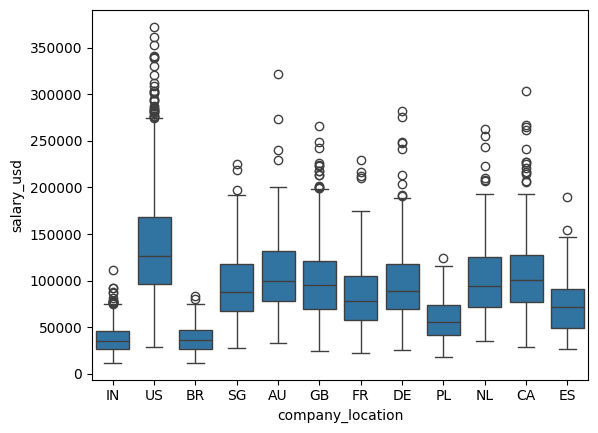

In [34]:
sns.boxplot(df, x = df['company_location'], y = df['salary_usd'] )

<Axes: xlabel='employment_type', ylabel='salary_usd'>

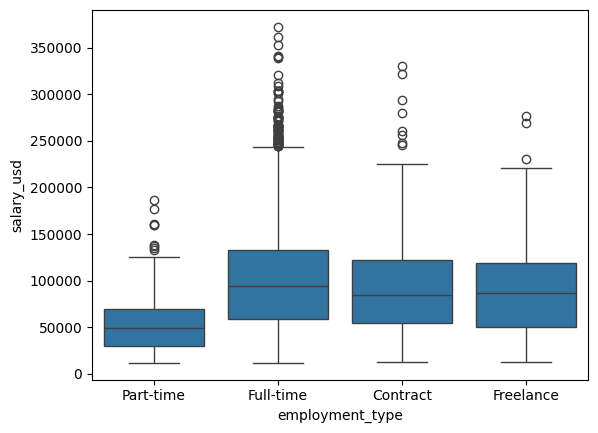

In [35]:
sns.boxplot(df, x = df['employment_type'], y = df['salary_usd'] )

<Axes: xlabel='employee_residence', ylabel='salary_usd'>

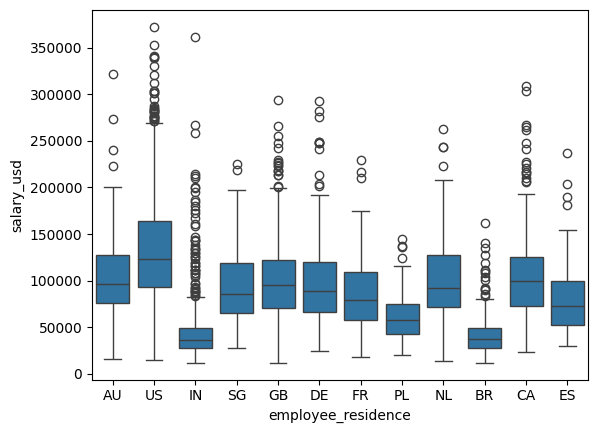

In [31]:
sns.boxplot(df, x = df['employee_residence'], y = df['salary_usd'] )

<Axes: xlabel='switched_jobs_last_year', ylabel='salary_usd'>

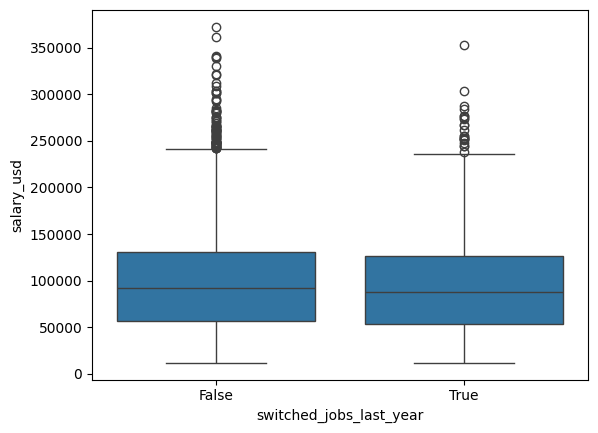

In [37]:
sns.boxplot(df, x = df['switched_jobs_last_year'], y= df['salary_usd'] )

<Axes: xlabel='manages_people', ylabel='salary_usd'>

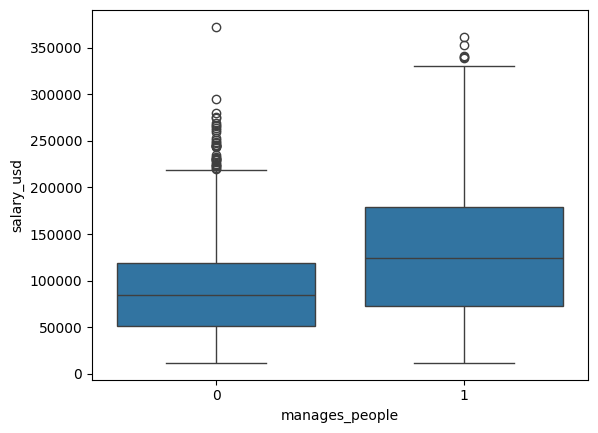

In [32]:
sns.boxplot(df, x = df['manages_people'], y= df['salary_usd'] )

<Axes: xlabel='employee_residence', ylabel='company_location'>

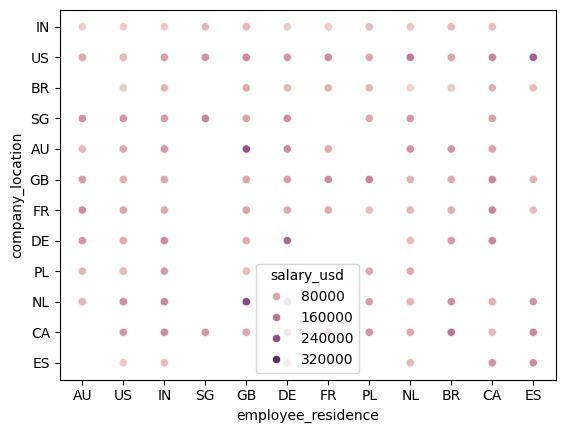

In [39]:
sns.scatterplot(df,x='employee_residence', y='company_location', hue='salary_usd')

In [4]:
from sklearn.preprocessing import OneHotEncoder      # for nominal categorical data
from sklearn.preprocessing import StandardScaler 
from sklearn.preprocessing import OrdinalEncoder    # for feature scaling
from sklearn.compose import ColumnTransformer     


In [33]:
df.columns



Index(['job_title', 'experience_level', 'employment_type', 'company_size',
       'company_location', 'employee_residence', 'industry',
       'years_experience', 'education_level', 'has_ml_in_title',
       'manages_people', 'certifications_count', 'weekly_hours',
       'salary_currency', 'salary_usd', 'job_satisfaction_score',
       'interviews_to_offer', 'switched_jobs_last_year'],
      dtype='object')

In [34]:
df.drop("salary_currency", axis=1, inplace=True)



In [35]:
# column transformer for one hot encoding of required columns 

categorical_cols = [
    "job_title",
    "experience_level",
    "employment_type",
    "company_location",
    "industry",
    "employee_residence",
]

ordinal_cols = ["education_level"]


preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore",sparse_output=False), categorical_cols),
        ("ordinal",OrdinalEncoder(categories=[["Bootcamp", "Self-taught", "Bachelors", "Masters", "PhD"]]), ordinal_cols)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

X = df

X_encoded = preprocessor.fit_transform(X)

X_encoded = pd.DataFrame(
    X_encoded,
    columns=preprocessor.get_feature_names_out(),
    index=X.index
)



In [36]:
X_encoded['switched_jobs_last_year']= X_encoded['switched_jobs_last_year'].astype(int)
X_encoded.sample(15, ignore_index=True)



,job_title_AI Engineer,job_title_Analytics Engineer,job_title_Business Intelligence Analyst,job_title_Computer Vision Engineer,job_title_Data Analyst,job_title_Data Engineer,job_title_Data Science Manager,job_title_Data Scientist,job_title_LLM Engineer,job_title_MLOps Engineer,...,company_size,years_experience,has_ml_in_title,manages_people,certifications_count,weekly_hours,salary_usd,job_satisfaction_score,interviews_to_offer,switched_jobs_last_year
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,11.1,1,0,1,35.7,213816,6.8,5,0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2,1.9,1,1,1,42.9,171884,9.4,3,0
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0.0,1,0,2,46.4,85800,8.6,7,0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,5.8,1,0,2,39.1,85518,5.0,3,0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,2,1.7,0,0,2,31.1,71324,8.3,5,1
5,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,5.5,1,0,0,40.2,80588,8.3,4,1
6,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2,6.7,1,0,2,51.3,66476,5.7,1,1
7,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0,7.7,0,1,3,43.9,107311,5.9,6,0
8,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1,12.3,0,0,2,52.4,82037,4.6,3,0
9,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,10.0,0,0,2,49.8,164463,6.5,8,0


In [37]:
categories= [
    'years_experience',
    'weekly_hours',
    'job_satisfaction_score',
    'interviews_to_offer'
]

preprocessing = ColumnTransformer(
    transformers=[
        ("scaling", StandardScaler(), categories)
    ],
    remainder= 'passthrough',
    verbose_feature_names_out= False
)

X_scaled = preprocessing.fit_transform(X_encoded)


New_Frame= pd.DataFrame(
    X_scaled,
    columns = preprocessing.get_feature_names_out(),
    index = X_encoded.index
)

New_Frame = New_Frame[X_encoded.columns]


In [38]:
pd.set_option("display.max_columns", None)

In [39]:
New_Frame

,job_title_AI Engineer,job_title_Analytics Engineer,job_title_Business Intelligence Analyst,job_title_Computer Vision Engineer,job_title_Data Analyst,job_title_Data Engineer,job_title_Data Science Manager,job_title_Data Scientist,job_title_LLM Engineer,job_title_MLOps Engineer,job_title_Machine Learning Engineer,job_title_Research Scientist,experience_level_0,experience_level_1,experience_level_2,experience_level_3,experience_level_4,employment_type_Contract,employment_type_Freelance,employment_type_Full-time,employment_type_Part-time,company_location_AU,company_location_BR,company_location_CA,company_location_DE,company_location_ES,company_location_FR,company_location_GB,company_location_IN,company_location_NL,company_location_PL,company_location_SG,company_location_US,industry_Consulting,industry_Education,industry_Energy,industry_Finance,industry_Government,industry_Healthcare,industry_Manufacturing,industry_Media,industry_Retail,industry_Technology,employee_residence_AU,employee_residence_BR,employee_residence_CA,employee_residence_DE,employee_residence_ES,employee_residence_FR,employee_residence_GB,employee_residence_IN,employee_residence_NL,employee_residence_PL,employee_residence_SG,employee_residence_US,education_level,company_size,years_experience,has_ml_in_title,manages_people,certifications_count,weekly_hours,salary_usd,job_satisfaction_score,interviews_to_offer,switched_jobs_last_year
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0,1.252729,0,1,0,0.595004,23844,-0.868897,1.147877,1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,2,-0.157964,1,0,1,-0.446977,170132,0.230676,-0.924702,0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1,-1.734621,1,0,1,1.750951,83059,-0.575678,-1.753733,0
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,3.0,1,0.277691,0,0,2,-0.528382,29531,-0.795592,-0.09567,0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,1,-1.070766,0,0,2,0.627566,70105,-1.528641,-0.510186,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,3.0,1,0.194709,0,0,2,-0.577225,38810,0.45059,-1.339218,0
4996,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1,1.024528,1,1,1,1.685828,123368,-0.868897,0.733361,0
4997,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2.0,1,-0.054237,0,0,3,1.21368,86123,0.230676,0.318846,1
4998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.

In [40]:
New_Frame.shape


(5000, 66)

In [41]:
New_Frame.columns

Index(['job_title_AI Engineer', 'job_title_Analytics Engineer',
       'job_title_Business Intelligence Analyst',
       'job_title_Computer Vision Engineer', 'job_title_Data Analyst',
       'job_title_Data Engineer', 'job_title_Data Science Manager',
       'job_title_Data Scientist', 'job_title_LLM Engineer',
       'job_title_MLOps Engineer', 'job_title_Machine Learning Engineer',
       'job_title_Research Scientist', 'experience_level_0',
       'experience_level_1', 'experience_level_2', 'experience_level_3',
       'experience_level_4', 'employment_type_Contract',
       'employment_type_Freelance', 'employment_type_Full-time',
       'employment_type_Part-time', 'company_location_AU',
       'company_location_BR', 'company_location_CA', 'company_location_DE',
       'company_location_ES', 'company_location_FR', 'company_location_GB',
       'company_location_IN', 'company_location_NL', 'company_location_PL',
       'company_location_SG', 'company_location_US', 'industry_Consul

In [42]:
New_Frame.drop(columns = ['employee_residence_AU', 'employee_residence_BR',
       'employee_residence_CA', 'employee_residence_DE',
       'employee_residence_ES', 'employee_residence_FR',
       'employee_residence_GB',
       'employee_residence_NL', 'employee_residence_PL',
       'employee_residence_SG', 'employee_residence_US'], inplace =True)

In [43]:
New_Frame

,job_title_AI Engineer,job_title_Analytics Engineer,job_title_Business Intelligence Analyst,job_title_Computer Vision Engineer,job_title_Data Analyst,job_title_Data Engineer,job_title_Data Science Manager,job_title_Data Scientist,job_title_LLM Engineer,job_title_MLOps Engineer,job_title_Machine Learning Engineer,job_title_Research Scientist,experience_level_0,experience_level_1,experience_level_2,experience_level_3,experience_level_4,employment_type_Contract,employment_type_Freelance,employment_type_Full-time,employment_type_Part-time,company_location_AU,company_location_BR,company_location_CA,company_location_DE,company_location_ES,company_location_FR,company_location_GB,company_location_IN,company_location_NL,company_location_PL,company_location_SG,company_location_US,industry_Consulting,industry_Education,industry_Energy,industry_Finance,industry_Government,industry_Healthcare,industry_Manufacturing,industry_Media,industry_Retail,industry_Technology,employee_residence_IN,education_level,company_size,years_experience,has_ml_in_title,manages_people,certifications_count,weekly_hours,salary_usd,job_satisfaction_score,interviews_to_offer,switched_jobs_last_year
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0,1.252729,0,1,0,0.595004,23844,-0.868897,1.147877,1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,3.0,2,-0.157964,1,0,1,-0.446977,170132,0.230676,-0.924702,0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,-1.734621,1,0,1,1.750951,83059,-0.575678,-1.753733,0
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,1,0.277691,0,0,2,-0.528382,29531,-0.795592,-0.09567,0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1,-1.070766,0,0,2,0.627566,70105,-1.528641,-0.510186,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,1,0.194709,0,0,2,-0.577225,38810,0.45059,-1.339218,0
4996,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1,1.024528,1,1,1,1.685828,123368,-0.868897,0.733361,0
4997,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,1,-0.054237,0,0,3,1.21368,86123,0.230676,0.318846,1
4998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,1,0.941546,1,0,1,-0.967968,76001,-0.502373,-0.510186,1


In [44]:
New_Frame.to_csv('Cleaned_data_version_1.csv')

In [48]:
print(preprocessing.named_transformers_["scaling"].mean_)
print(preprocessing.named_transformers_["scaling"].scale_)


print(preprocessing.named_transformers_["scaling"].feature_names_in_)

[ 8.36144 44.3454   6.68532  5.2308 ]
[4.82032583 6.14214644 1.36416586 2.41245339]
['years_experience' 'weekly_hours' 'job_satisfaction_score'
 'interviews_to_offer']
